Data Summery & Cleaning

Initial Data Head:
    age  sex  cp  trestbps  chol  fbs  restecg  thalach  exang  oldpeak  slope  \
0   63    1   1       145   233    1        2      150      0      2.3      3   
1   67    1   4       160   286    0        2      108      1      1.5      2   
2   67    1   4       120   229    0        2      129      1      2.6      2   
3   37    1   3       130   250    0        0      187      0      3.5      3   
4   41    0   2       130   204    0        2      172      0      1.4      1   

   ca  thal  num  
0   0     6    0  
1   3     3    1  
2   2     7    1  
3   0     3    0  
4   0     3    0  

Initial Data Summary:
               age         sex          cp    trestbps        chol         fbs  \
count  303.000000  303.000000  303.000000  303.000000  303.000000  303.000000   
mean    54.438944    0.679868    3.158416  131.689769  246.693069    0.148515   
std      9.038662    0.467299    0.960126   17.599748   51.776918    0.356198   
min     29.000000    0.000000  

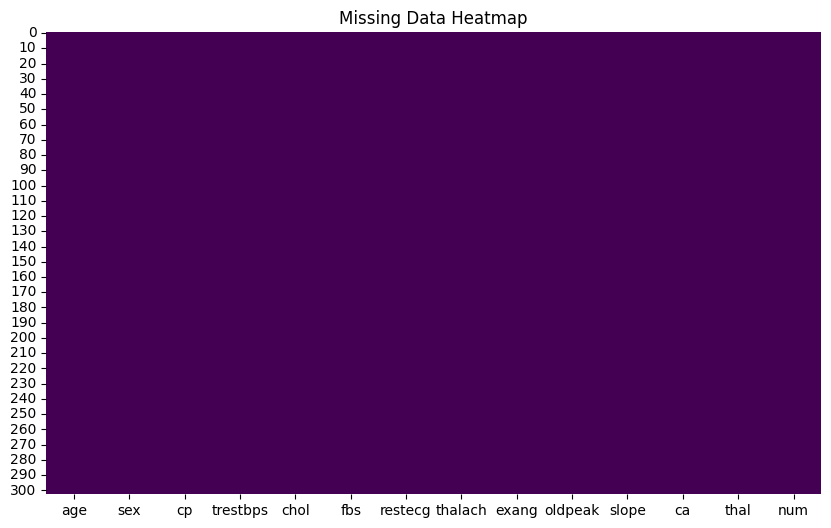

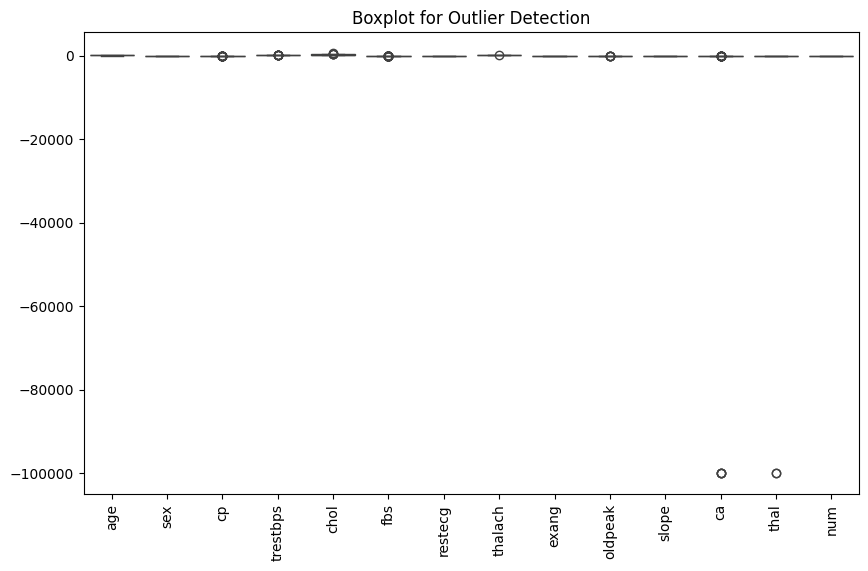


Cleaned Data Summary:
               age         sex          cp    trestbps        chol    fbs  \
count  216.000000  216.000000  216.000000  216.000000  216.000000  216.0   
mean    53.250000    0.662037    3.305556  128.273148  243.268519    0.0   
std      9.100089    0.474115    0.783057   14.849772   45.097952    0.0   
min     29.000000    0.000000    2.000000   94.000000  131.000000    0.0   
25%     45.750000    0.000000    3.000000  120.000000  210.750000    0.0   
50%     54.000000    1.000000    4.000000  130.000000  240.000000    0.0   
75%     60.000000    1.000000    4.000000  140.000000  271.000000    0.0   
max     76.000000    1.000000    4.000000  170.000000  360.000000    0.0   

          restecg     thalach       exang     oldpeak       slope          ca  \
count  216.000000  216.000000  216.000000  216.000000  216.000000  216.000000   
mean     0.916667  150.736111    0.314815    0.899537    1.537037    0.462963   
std      0.994169   22.488029    0.465521    1.0

In [18]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

data = pd.read_csv('heart_disease_dataset.csv')

#summary statistics
print("Initial Data Head:\n", data.head())
print("\nInitial Data Summary:\n", data.describe(include='all'))

#erroneous data
erroneous_ca = data[(data['ca'] < 0) | (data['ca'] > 3)]
erroneous_thal = data[(data['thal'] < 0) | (data['thal'] > 7)]

#missing data
missing_data = data.isnull().sum()

#outliers
Q1 = data.quantile(0.25)
Q3 = data.quantile(0.75)
IQR = Q3 - Q1
outliers = data[((data < (Q1 - 1.5 * IQR)) | (data > (Q3 + 1.5 * IQR))).any(axis=1)]

#Display erroneous, missing, and outlier data
print("\nErroneous 'ca' Data:\n", erroneous_ca)
print("\nErroneous 'thal' Data:\n", erroneous_thal)
print("\nMissing Data:\n", missing_data)
print("\nOutliers:\n", outliers)

#Plot missing data
plt.figure(figsize=(10, 6))
sns.heatmap(data.isnull(), cbar=False, cmap='viridis')
plt.title('Missing Data Heatmap')
plt.show()

#Plot outliers
plt.figure(figsize=(10, 6))
sns.boxplot(data=data)
plt.title('Boxplot for Outlier Detection')
plt.xticks(rotation=90)
plt.show()

#Cleaning
data.loc[(data['ca'] < 0) | (data['ca'] > 3), 'ca'] = np.nan
data.loc[(data['thal'] < 0) | (data['thal'] > 7), 'thal'] = np.nan

#replace missing with median
data = data.fillna(data.median())

#Remove outliers
data_cleaned = data[~((data < (Q1 - 1.5 * IQR)) | (data > (Q3 + 1.5 * IQR))).any(axis=1)]

#cleaned data summary
print("\nCleaned Data Summary:\n", data_cleaned.describe(include='all'))

K-Means Clustering

C:\Users\ARTA PC\AppData\Local\Temp\ipykernel_22748\2701638315.py:19: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data_cleaned[f'kmeans_{k}'] = kmeans.labels_
C:\Users\ARTA PC\AppData\Local\Temp\ipykernel_22748\2701638315.py:19: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data_cleaned[f'kmeans_{k}'] = kmeans.labels_
C:\Users\ARTA PC\AppData\Local\Temp\ipykernel_22748\2701638315.py:19: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,c

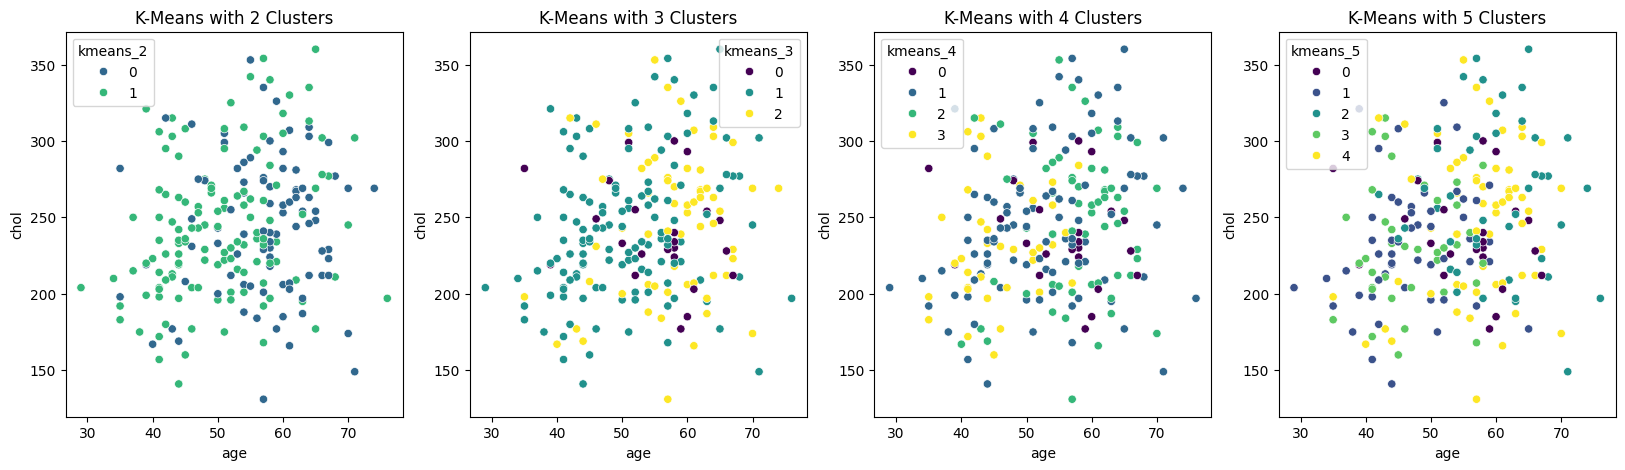

In [22]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler

# Standardize the data
scaler = StandardScaler()
data_scaled = scaler.fit_transform(data_cleaned.drop(columns=['num']))

# K-Means clustering with different number of clusters
kmeans_params = [2, 3, 4, 5]
kmeans_results = []

for k in kmeans_params:
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans.fit(data_scaled)
    data_cleaned[f'kmeans_{k}'] = kmeans.labels_
    kmeans_results.append(data_cleaned[f'kmeans_{k}'])

# Plot the results
fig, axes = plt.subplots(1, len(kmeans_params), figsize=(20, 5))

for ax, k, result in zip(axes, kmeans_params, kmeans_results):
    sns.scatterplot(x=data_cleaned['age'], y=data_cleaned['chol'], hue=result, ax=ax, palette='viridis')
    ax.set_title(f'K-Means with {k} Clusters')

plt.show()

Hierarchical Clustering

C:\Users\ARTA PC\AppData\Local\Temp\ipykernel_22748\2614297230.py:12: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data_cleaned[f'hierarchical_{method}'] = labels
C:\Users\ARTA PC\AppData\Local\Temp\ipykernel_22748\2614297230.py:12: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data_cleaned[f'hierarchical_{method}'] = labels
C:\Users\ARTA PC\AppData\Local\Temp\ipykernel_22748\2614297230.py:12: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_ind

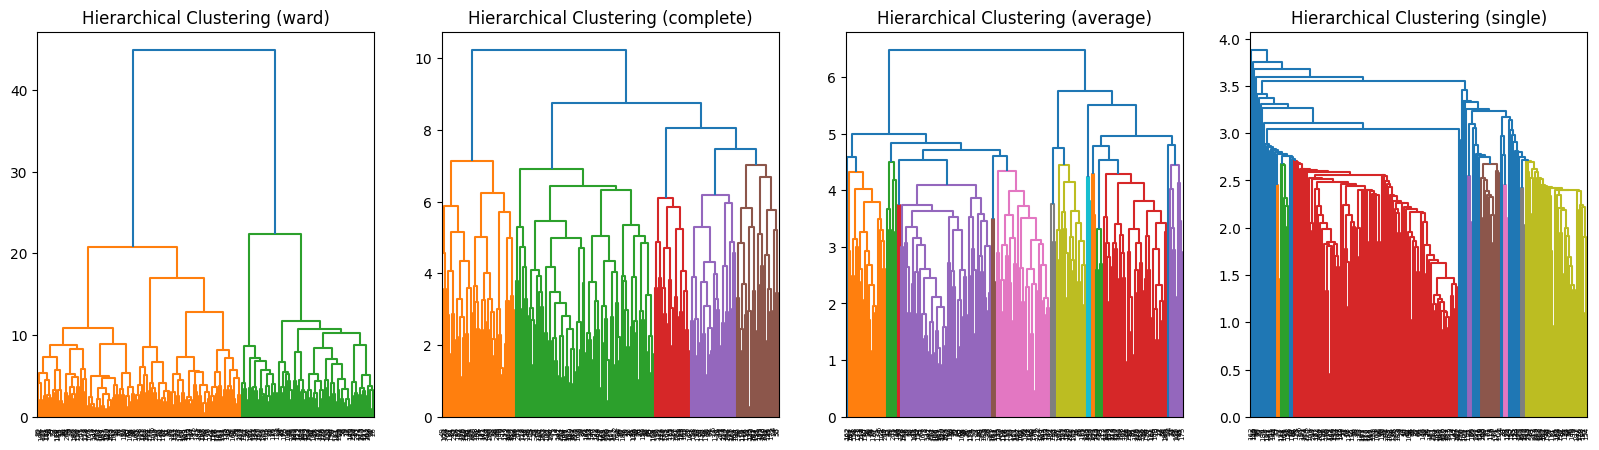

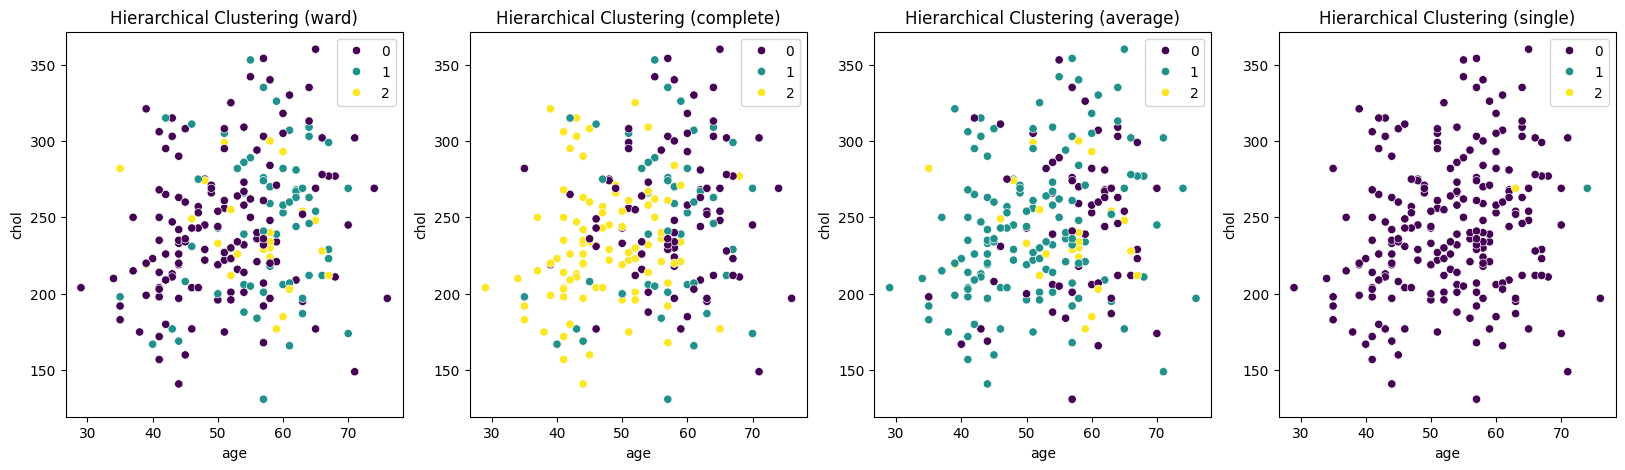

In [19]:
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.cluster import AgglomerativeClustering

# Hierarchical clustering with different linkage methods
linkage_methods = ['ward', 'complete', 'average', 'single']
hierarchical_results = []

for method in linkage_methods:
    Z = linkage(data_scaled, method=method)
    cluster = AgglomerativeClustering(n_clusters=3, linkage=method)
    labels = cluster.fit_predict(data_scaled)
    data_cleaned[f'hierarchical_{method}'] = labels
    hierarchical_results.append((Z, labels))

# Plot the dendrograms
fig, axes = plt.subplots(1, len(linkage_methods), figsize=(20, 5))

for ax, method, result in zip(axes, linkage_methods, hierarchical_results):
    Z, labels = result
    dendrogram(Z, ax=ax)
    ax.set_title(f'Hierarchical Clustering ({method})')

plt.show()

# Plot the scatter plots
fig, axes = plt.subplots(1, len(linkage_methods), figsize=(20, 5))

for ax, method, result in zip(axes, linkage_methods, hierarchical_results):
    _, labels = result
    sns.scatterplot(x=data_cleaned['age'], y=data_cleaned['chol'], hue=labels, ax=ax, palette='viridis')
    ax.set_title(f'Hierarchical Clustering ({method})')

plt.show()

Mean Shift Clustering

C:\Users\ARTA PC\AppData\Local\Temp\ipykernel_22748\1666133191.py:10: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data_cleaned[f'meanshift_{bandwidth}'] = ms.labels_
C:\Users\ARTA PC\AppData\Local\Temp\ipykernel_22748\1666133191.py:10: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data_cleaned[f'meanshift_{bandwidth}'] = ms.labels_
C:\Users\ARTA PC\AppData\Local\Temp\ipykernel_22748\1666133191.py:10: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc

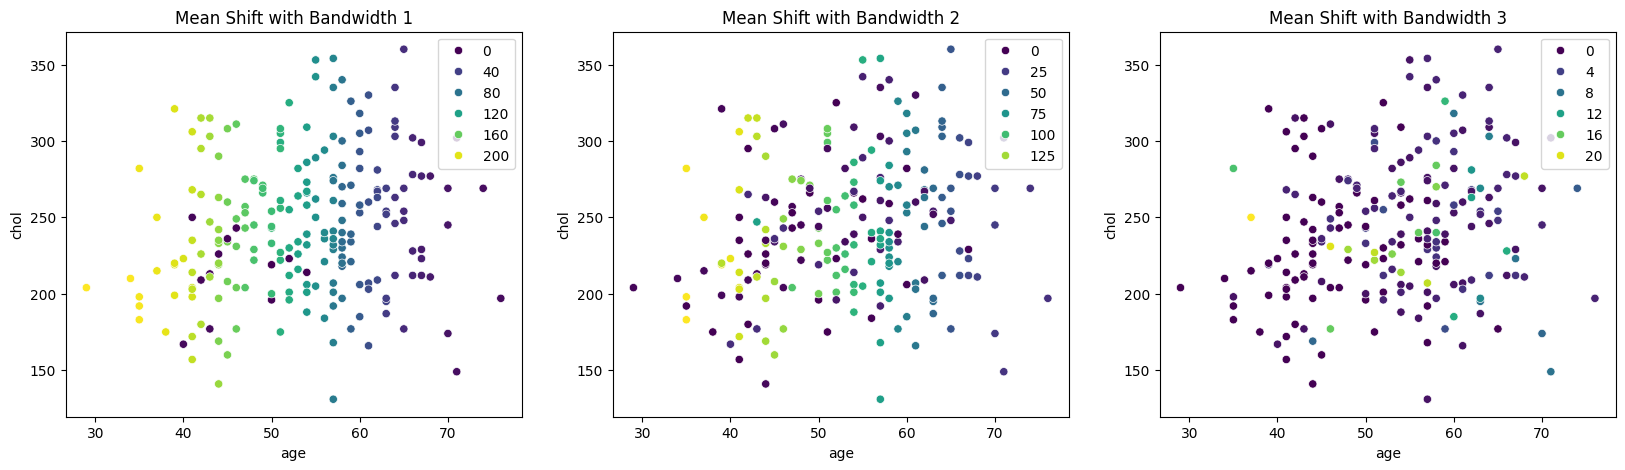

In [20]:
from sklearn.cluster import MeanShift

# Mean Shift clustering with different bandwidths
bandwidths = [1, 2, 3]
meanshift_results = []

for bandwidth in bandwidths:
    ms = MeanShift(bandwidth=bandwidth)
    ms.fit(data_scaled)
    data_cleaned[f'meanshift_{bandwidth}'] = ms.labels_
    meanshift_results.append(ms.labels_)

# Plot the results
fig, axes = plt.subplots(1, len(bandwidths), figsize=(20, 5))

for ax, bandwidth, result in zip(axes, bandwidths, meanshift_results):
    sns.scatterplot(x=data_cleaned['age'], y=data_cleaned['chol'], hue=result, ax=ax, palette='viridis')
    ax.set_title(f'Mean Shift with Bandwidth {bandwidth}')

plt.show()

DBSCAN Clustering

C:\Users\ARTA PC\AppData\Local\Temp\ipykernel_22748\1267729607.py:12: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data_cleaned[f'dbscan_{eps}_{min_samples}'] = labels
C:\Users\ARTA PC\AppData\Local\Temp\ipykernel_22748\1267729607.py:12: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data_cleaned[f'dbscan_{eps}_{min_samples}'] = labels
C:\Users\ARTA PC\AppData\Local\Temp\ipykernel_22748\1267729607.py:12: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .l

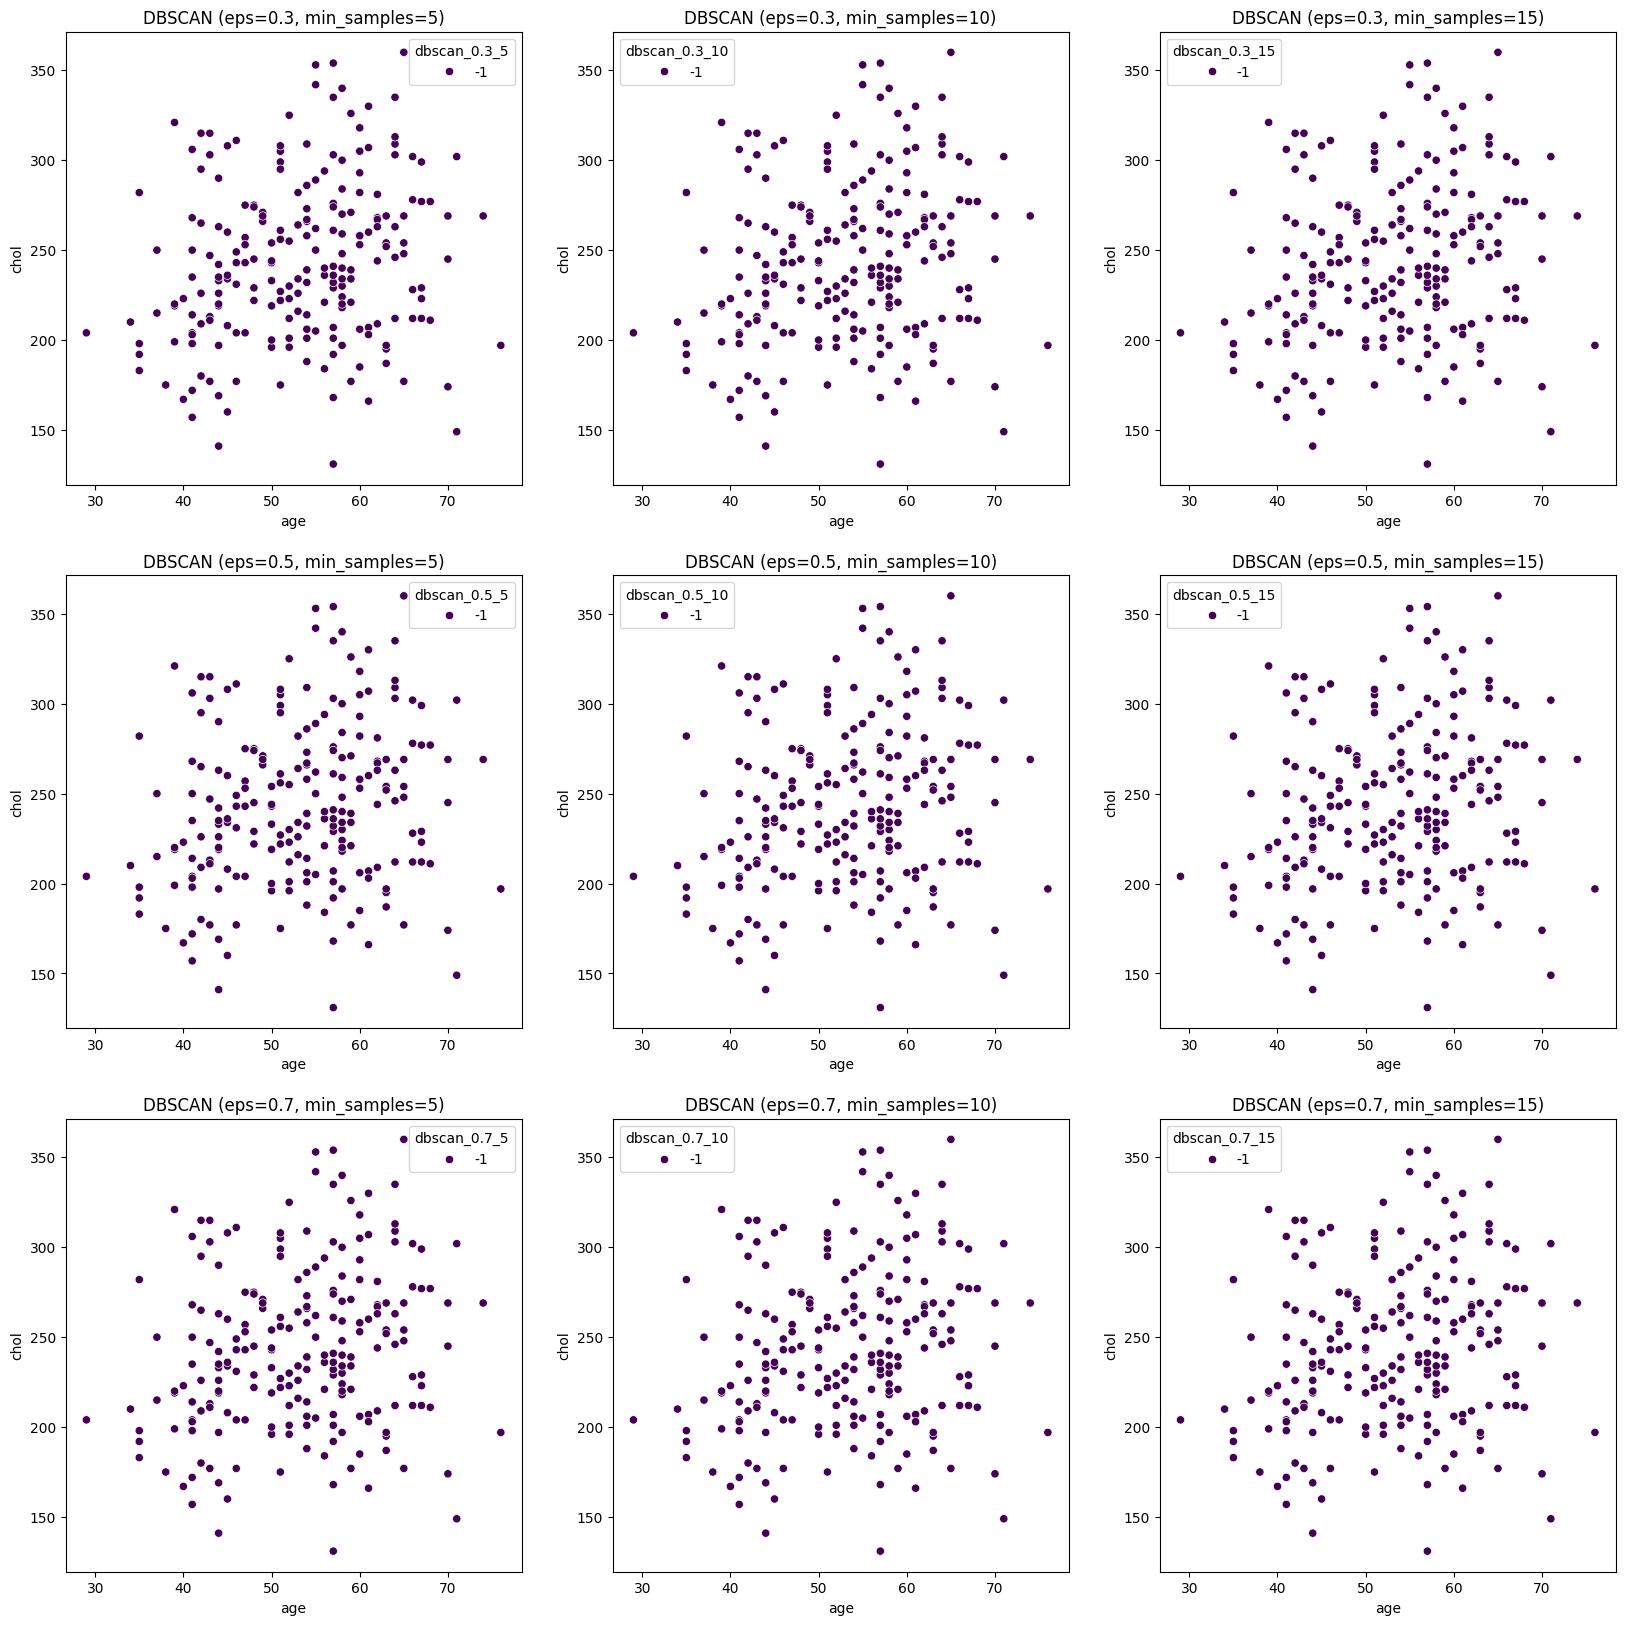

In [21]:
from sklearn.cluster import DBSCAN

# DBSCAN clustering with different eps and min_samples
eps_values = [0.3, 0.5, 0.7]
min_samples_values = [5, 10, 15]
dbscan_results = []

for eps in eps_values:
    for min_samples in min_samples_values:
        dbscan = DBSCAN(eps=eps, min_samples=min_samples)
        labels = dbscan.fit_predict(data_scaled)
        data_cleaned[f'dbscan_{eps}_{min_samples}'] = labels
        dbscan_results.append((eps, min_samples, labels))

# Plot the results
fig, axes = plt.subplots(len(eps_values), len(min_samples_values), figsize=(20, 20))

for i, eps in enumerate(eps_values):
    for j, min_samples in enumerate(min_samples_values):
        labels = data_cleaned[f'dbscan_{eps}_{min_samples}']
        sns.scatterplot(x=data_cleaned['age'], y=data_cleaned['chol'], hue=labels, ax=axes[i, j], palette='viridis')
        axes[i, j].set_title(f'DBSCAN (eps={eps}, min_samples={min_samples})')

plt.show()

Comparison

In [23]:
from sklearn.metrics import silhouette_score, calinski_harabasz_score, davies_bouldin_score

def evaluate_clustering(data_cleaned, labels):
    if len(set(labels)) > 1:
        silhouette = silhouette_score(data_cleaned, labels)
        calinski = calinski_harabasz_score(data_cleaned, labels)
        davies = davies_bouldin_score(data_cleaned, labels)
        return silhouette, calinski, davies
    else:
        return None, None, None

# Evaluating K-Means
print("K-Means Clustering Evaluation")
for k in kmeans_params:
    labels = data_cleaned[f'kmeans_{k}']
    silhouette, calinski, davies = evaluate_clustering(data_scaled, labels)
    print(f'K={k}: Silhouette={silhouette}, Calinski-Harabasz={calinski}, Davies-Bouldin={davies}')

# Evaluating Hierarchical
print("\nHierarchical Clustering Evaluation")
for method in linkage_methods:
    labels = data_cleaned[f'hierarchical_{method}']
    silhouette, calinski, davies = evaluate_clustering(data_scaled, labels)
    print(f'Method={method}: Silhouette={silhouette}, Calinski-Harabasz={calinski}, Davies-Bouldin={davies}')

# Evaluating Mean Shift
print("\nMean Shift Clustering Evaluation")
for bandwidth in bandwidths:
    labels = data_cleaned[f'meanshift_{bandwidth}']
    silhouette, calinski, davies = evaluate_clustering(data_scaled, labels)
    print(f'Bandwidth={bandwidth}: Silhouette={silhouette}, Calinski-Harabasz={calinski}, Davies-Bouldin={davies}')

# Evaluating DBSCAN
print("\nDBSCAN Clustering Evaluation")
for eps in eps_values:
    for min_samples in min_samples_values:
        labels = data_cleaned[f'dbscan_{eps}_{min_samples}']
        silhouette, calinski, davies = evaluate_clustering(data_scaled, labels)
        print(f'Eps={eps}, Min_samples={min_samples}: Silhouette={silhouette}, Calinski-Harabasz={calinski}, Davies-Bouldin={davies}')

K-Means Clustering Evaluation
K=2: Silhouette=0.2086106838375646, Calinski-Harabasz=52.605099534151876, Davies-Bouldin=1.9335597086759089
K=3: Silhouette=0.23342268725682014, Calinski-Harabasz=41.225262409375155, Davies-Bouldin=1.6074711072682624
K=4: Silhouette=0.17389281667455586, Calinski-Harabasz=34.29685851138339, Davies-Bouldin=1.9856451332164733
K=5: Silhouette=0.18413693321871835, Calinski-Harabasz=35.02587287255432, Davies-Bouldin=1.864193869064114

Hierarchical Clustering Evaluation
Method=ward: Silhouette=0.2329164078653199, Calinski-Harabasz=41.19921355219627, Davies-Bouldin=1.588608940100486
Method=complete: Silhouette=0.18151777012286183, Calinski-Harabasz=40.08253526550272, Davies-Bouldin=2.0432797943519856
Method=average: Silhouette=0.2329164078653199, Calinski-Harabasz=41.19921355219627, Davies-Bouldin=1.588608940100486
Method=single: Silhouette=0.3578015831255108, Calinski-Harabasz=7.314910552313885, Davies-Bouldin=0.43889890319010233

Mean Shift Clustering Evaluation